# Steel Plates Faults: Exploratory Data Analysis

This notebook explores the cleaned dataset produced by `prepare_data.py`. No models are trained here.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Works whether the notebook is run from notebooks/ or the repo root.
DATA_PATH = Path("../data/steel_plates_clean.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/steel_plates_clean.csv")

TARGET = "Fault_Type"
df = pd.read_csv(DATA_PATH)
features = df.drop(columns=TARGET)

## 1. Shape, columns, data types and missing values

In [2]:
print("Shape:", df.shape)
print("Number of features:", features.shape[1])
print("\nColumns:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:2d}. {col}")

Shape: (1941, 28)
Number of features: 27

Columns:
 1. X_Minimum
 2. X_Maximum
 3. Y_Minimum
 4. Y_Maximum
 5. Pixels_Areas
 6. X_Perimeter
 7. Y_Perimeter
 8. Sum_of_Luminosity
 9. Minimum_of_Luminosity
10. Maximum_of_Luminosity
11. Length_of_Conveyer
12. TypeOfSteel_A300
13. TypeOfSteel_A400
14. Steel_Plate_Thickness
15. Edges_Index
16. Empty_Index
17. Square_Index
18. Outside_X_Index
19. Edges_X_Index
20. Edges_Y_Index
21. Outside_Global_Index
22. LogOfAreas
23. Log_X_Index
24. Log_Y_Index
25. Orientation_Index
26. Luminosity_Index
27. SigmoidOfAreas
28. Fault_Type


In [3]:
df.dtypes.value_counts()

int64      14
float64    13
object      1
Name: count, dtype: int64

In [4]:
pd.DataFrame({"dtype": df.dtypes.astype(str),
              "missing": df.isna().sum(),
              "unique_values": df.nunique()})

,dtype,missing,unique_values
X_Minimum,int64,0,962
X_Maximum,int64,0,994
Y_Minimum,int64,0,1939
Y_Maximum,int64,0,1940
Pixels_Areas,int64,0,920
X_Perimeter,int64,0,399
Y_Perimeter,int64,0,317
Sum_of_Luminosity,int64,0,1909
Minimum_of_Luminosity,int64,0,161
Maximum_of_Luminosity,int64,0,100


In [5]:
print("Total missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Total missing values: 0
Duplicate rows: 0


## 2. Class distribution

In [6]:
class_counts = df[TARGET].value_counts()
pd.DataFrame({"count": class_counts,
              "percent": (class_counts / len(df) * 100).round(1)})

,count,percent
Fault_Type,,
Other_Faults,673,34.7
Bumps,402,20.7
K_Scratch,391,20.1
Z_Scratch,190,9.8
Pastry,158,8.1
Stains,72,3.7
Dirtiness,55,2.8


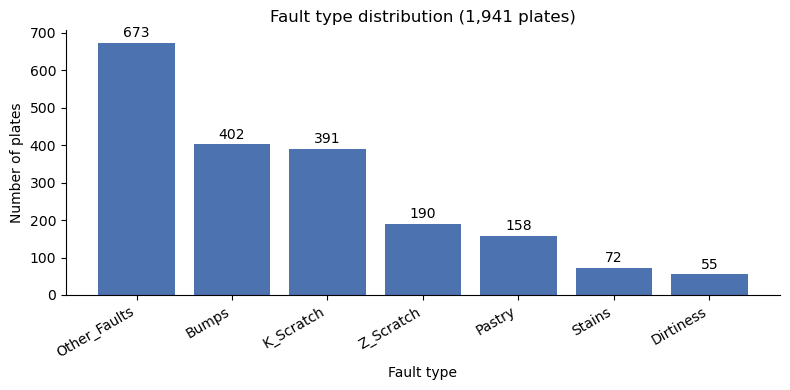

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(class_counts.index, class_counts.values, color="#4C72B0")
ax.bar_label(bars, padding=2)
ax.set_title("Fault type distribution (1,941 plates)")
ax.set_xlabel("Fault type")
ax.set_ylabel("Number of plates")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

The classes are imbalanced. Other_Faults is the largest class (about 35%), while Stains and Dirtiness each make up less than 4% of the data. This is why the train/test split is stratified, and why metrics such as F1 and MCC matter more than accuracy alone.

## 3. Summary statistics of the features

In [8]:
features.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
X_Minimum,1941.0,571.136,520.691,0.000,51.000,435.000,1053.000,1.705000e+03
X_Maximum,1941.0,617.964,497.627,4.000,192.000,467.000,1072.000,1.713000e+03
Y_Minimum,1941.0,1650684.868,1774578.415,6712.000,471253.000,1204128.000,2183073.000,1.298766e+07
Y_Maximum,1941.0,1650738.705,1774590.089,6724.000,471281.000,1204136.000,2183084.000,1.298769e+07
Pixels_Areas,1941.0,1893.878,5168.460,2.000,84.000,174.000,822.000,1.526550e+05
X_Perimeter,1941.0,111.855,301.209,2.000,15.000,26.000,84.000,1.044900e+04
Y_Perimeter,1941.0,82.966,426.483,1.000,13.000,25.000,83.000,1.815200e+04
Sum_of_Luminosity,1941.0,206312.148,512293.588,250.000,9522.000,19202.000,83011.000,1.159141e+07
Minimum_of_Luminosity,1941.0,84.549,32.134,0.000,63.000,90.000,106.000,2.030000e+02
Maximum_of_Luminosity,1941.0,130.194,18.691,37.000,124.000,127.000,140.000,2.530000e+02


The features are on very different scales (for example Pixels_Areas and Sum_of_Luminosity reach into the thousands or millions, while the index features lie between 0 and 1), so scale-sensitive models such as KNN, SVM and Logistic Regression will need feature scaling.

## 4. Correlation heatmap of the 27 features

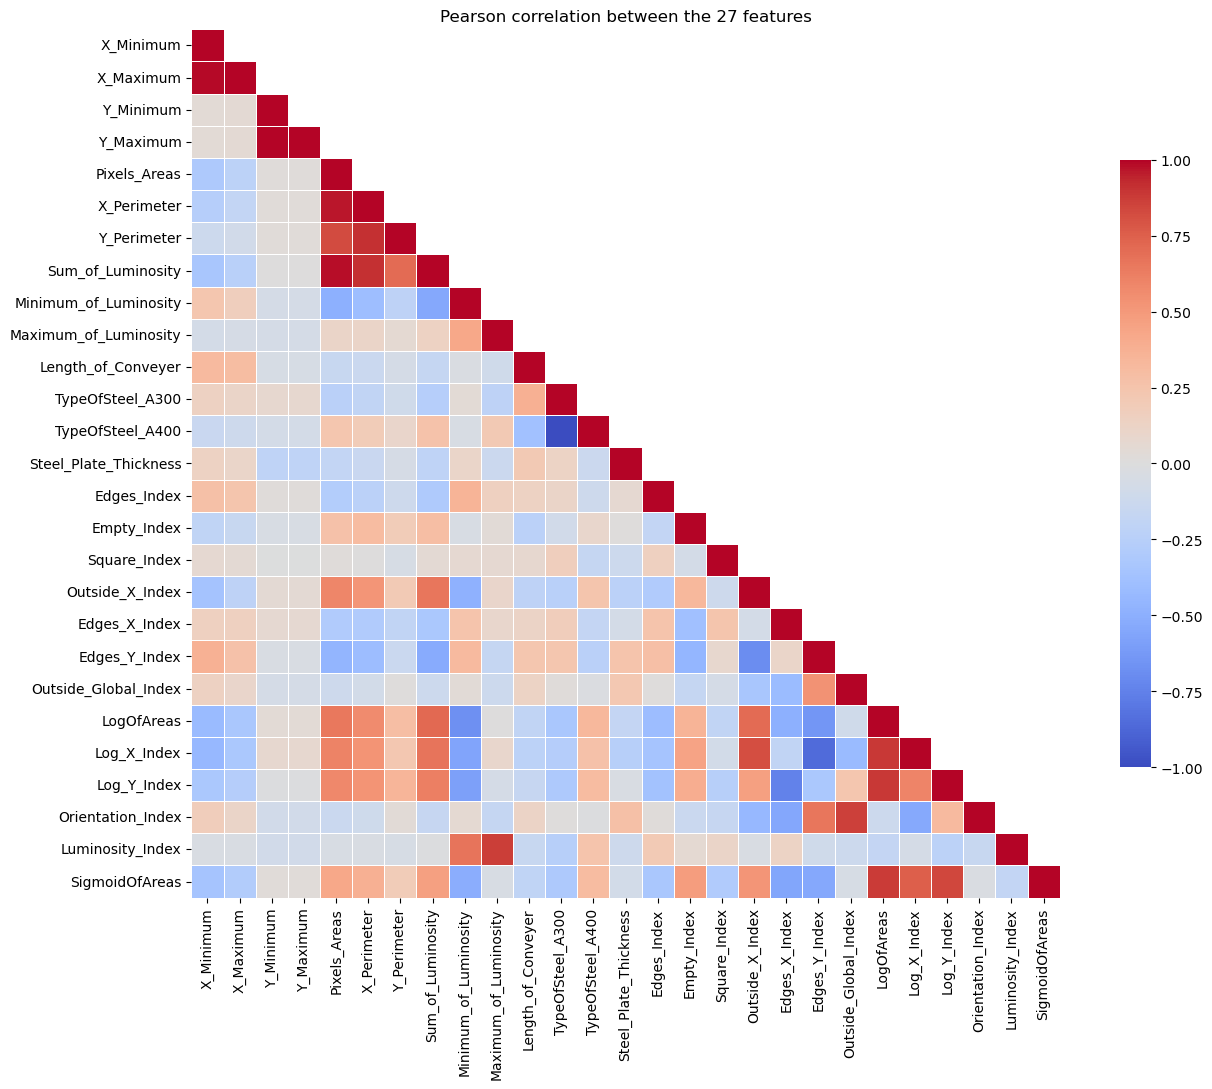

In [9]:
corr = features.corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.4, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Pearson correlation between the 27 features")
plt.tight_layout()
plt.show()

## 5. Binary, near-constant and highly correlated features

In [10]:
binary_cols = [c for c in features if features[c].nunique() == 2]
print("Binary features:", binary_cols)
print("Rows where TypeOfSteel_A300 + TypeOfSteel_A400 == 1:",
      int((features["TypeOfSteel_A300"] + features["TypeOfSteel_A400"] == 1).sum()),
      "of", len(features))

Binary features: ['TypeOfSteel_A300', 'TypeOfSteel_A400']
Rows where TypeOfSteel_A300 + TypeOfSteel_A400 == 1: 1941 of 1941


In [11]:
# Share of rows taken by each feature's most common value.
# A value close to 1.0 would mean the feature is nearly constant.
top_share = features.apply(lambda s: s.value_counts(normalize=True).iloc[0])
pd.DataFrame({"most_common_share": top_share.round(3),
              "unique_values": features.nunique()}).sort_values(
    "most_common_share", ascending=False).head(8)

,most_common_share,unique_values
TypeOfSteel_A300,0.600,2
TypeOfSteel_A400,0.600,2
Outside_Global_Index,0.552,3
Edges_Y_Index,0.422,648
Steel_Plate_Thickness,0.366,24
SigmoidOfAreas,0.237,388
Length_of_Conveyer,0.125,84
Maximum_of_Luminosity,0.100,100


In [12]:
upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high_pairs = (upper.stack()
              .loc[lambda s: s > 0.9]
              .sort_values(ascending=False)
              .rename("abs_correlation")
              .round(3))
high_pairs.to_frame()

abs_correlation
TypeOfSteel_A300 TypeOfSteel_A400             1.000
Y_Minimum        Y_Maximum                    1.000
X_Minimum        X_Maximum                    0.988
Pixels_Areas     Sum_of_Luminosity            0.979
                 X_Perimeter                  0.967
X_Perimeter      Sum_of_Luminosity            0.913
                 Y_Perimeter                  0.912

### Notes

- **Binary features:** TypeOfSteel_A300 and TypeOfSteel_A400 are the only binary (0/1) features. Every plate is exactly one of the two steel types, so one column is always 1 minus the other (correlation of -1). They carry the same information, and one of them could be dropped without losing anything.
- **Few distinct values:** Outside_Global_Index takes only 3 values (0, 0.5 and 1), and Steel_Plate_Thickness has only 24 distinct values, so both behave more like categories than continuous measurements.
- **Near-constant features:** none. The most common value of any feature covers at most about 60% of the rows (the steel type columns), so every feature varies enough to be potentially useful.
- **Very highly correlated pairs (|r| > 0.9):**
  - Y_Minimum and Y_Maximum (about 1.00) and X_Minimum and X_Maximum (about 0.99). Defects are small relative to the plate, so the minimum and maximum coordinates are almost the same number.
  - Pixels_Areas, Sum_of_Luminosity and X_Perimeter are strongly correlated with each other (0.91 to 0.98), and X_Perimeter is also strongly correlated with Y_Perimeter (0.91). All of these grow with the size of the defect.
- These redundant features are not a problem for tree-based models, but they can make Logistic Regression coefficients unstable and they break the independence assumption behind Naive Bayes. For now all 27 features are kept.